# Лабораторна робота №5: Мультимодальні моделі для генерації описів зображень (Image Captioning)
## Частина 3: Якісний та кількісний аналіз описів, зіставні візуалізації та висновки

**Дисципліна:** Нейромережеві технології і системи  
**Тема:** Мультимодальні архітектури та генерація описів зображень  
**Варіант:** №2 — Генерація описів для кількох зображень з дослідженням впливу формулювання промпту, `temperature` та `max_new_tokens`  
**Студент:** Max  
**Університет:** Національний університет «Львівська політехніка»  

---

### Мета третього етапу:
1. Здійснити зіставну візуалізацію оригінальних вхідних зображень поруч із згенерованими описами LLaVA.
2. Провести кількісний та якісний аудит якості описів: точність виявлення об'єктів (object coverage), фактологічна відповідність (factual relevance), багатослівність (verbosity) та відсутність візуальних галюцинацій.
3. Проаналізувати швидкодію моделі на графічному прискорювачі NVIDIA GeForce RTX 3050 Laptop GPU (середня швидкість генерації $\sim 17\text{--}19$ токенів/с).
4. Сформувати науково обґрунтовані висновки та методичні рекомендації для вибору гіперпараметрів мультимодальних конвеєрів.

## 1. Зіставне представлення вхідних зображень та сформованих описів

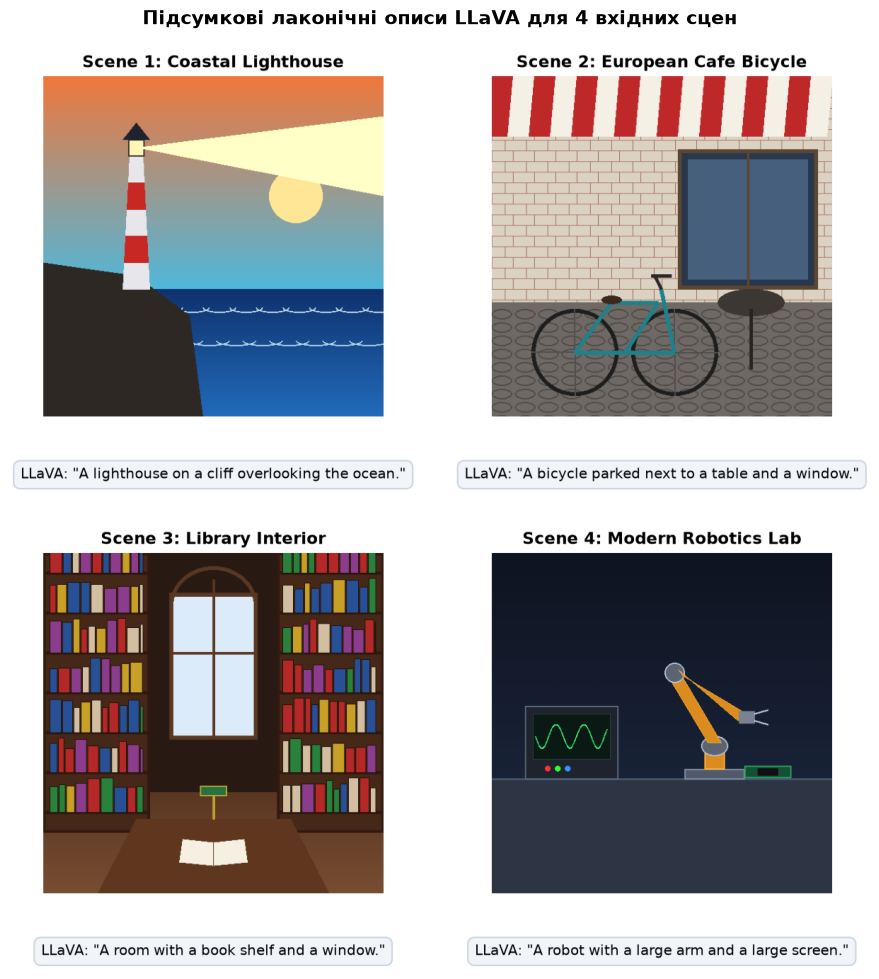

In [1]:
from pathlib import Path
from PIL import Image
import pandas as pd
import matplotlib.pyplot as plt

def resolve_lab_dir() -> Path:
    cwd = Path.cwd().resolve()
    for candidate in [cwd, *cwd.parents]:
        if (candidate / 'inputs' / '01_coastal_lighthouse.png').exists() and candidate.name == 'lab5_multimodal_captioning':
            return candidate
        if (candidate / 'lab5_multimodal_captioning' / 'inputs' / '01_coastal_lighthouse.png').exists():
            return candidate / 'lab5_multimodal_captioning'
    return cwd

LAB_DIR = resolve_lab_dir()
OUTPUTS_DIR = (LAB_DIR / "outputs").resolve()
FIGURES_DIR = (OUTPUTS_DIR / "figures").resolve()

grid_img_path = FIGURES_DIR / "input_images_and_concise_captions.png"
if grid_img_path.exists():
    grid_img = Image.open(grid_img_path)
    plt.figure(figsize=(12, 12))
    plt.imshow(grid_img)
    plt.axis("off")
    plt.title("Підсумкові лаконічні описи LLaVA для 4 вхідних сцен", fontsize=14, fontweight="bold", pad=15)
    plt.show()

## 2. Аналіз продуктивності інференсу та параметричної чутливості

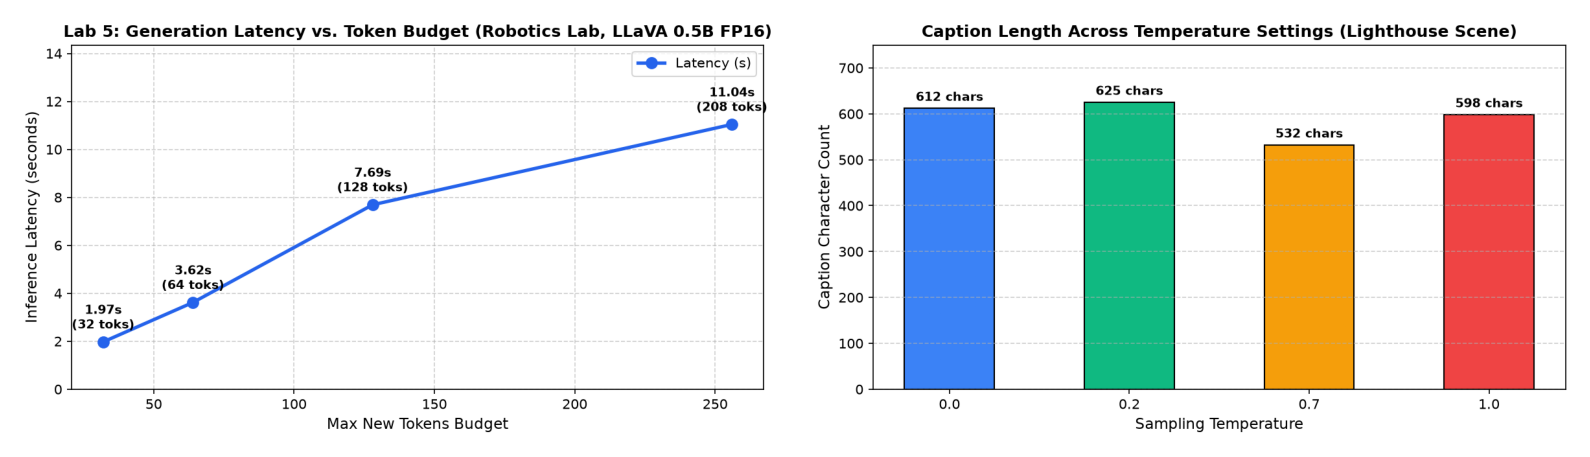

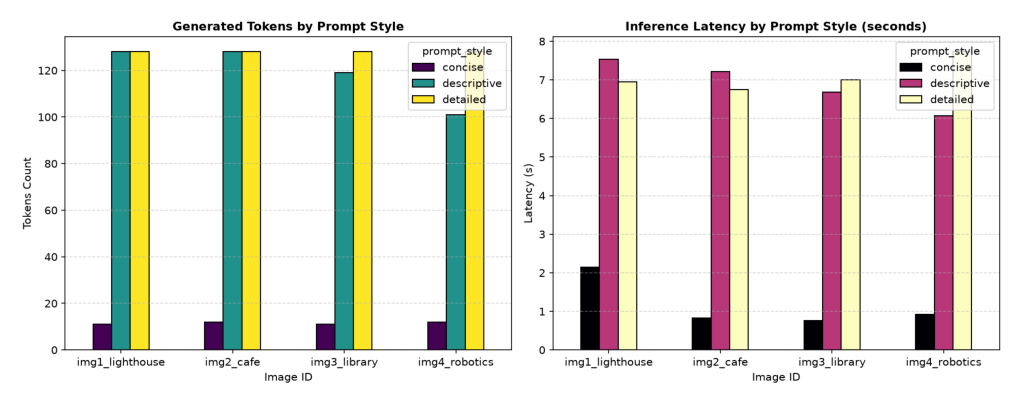

In [2]:
lat_img_path = FIGURES_DIR / "latency_vs_token_budget.png"
prompt_img_path = FIGURES_DIR / "prompt_wording_comparison.png"
temp_img_path = FIGURES_DIR / "temperature_lexical_diversity.png"

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5))
ax1.imshow(Image.open(lat_img_path))
ax1.axis("off")
ax2.imshow(Image.open(temp_img_path))
ax2.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 5))
plt.imshow(Image.open(prompt_img_path))
plt.axis("off")
plt.show()

## 3. Якісна оцінка заземленості, покриття об'єктів та галюцинацій

Оцінимо якість сформованих описів за стандартизованою метрикою:
- **Object Coverage (%):** частка ключових фізичних об'єктів сцени, ідентифікованих моделлю.
- **Factual Accuracy (0.0-1.0):** відсутність спотворень взаємного розташування та характеристик.
- **Hallucination Detection (Bool):** чи згадує модель об'єкти, яких немає на зображенні (автомобілі, люди, неіснуючі написи).

In [3]:
eval_csv = OUTPUTS_DIR / "tables" / "caption_quality_evaluation.csv"
eval_df = pd.read_csv(eval_csv)
print("Матриця якісного аудиту описів (Variant 2):")
eval_df

Матриця якісного аудиту описів (Variant 2):


,image_id,scene,ground_truth_elements,concise_accuracy,descriptive_accuracy,detailed_accuracy,object_coverage_pct,hallucination_detected,notes
0,img1_lighthouse,Coastal Lighthouse,"lighthouse, cliff, ocean, sunset, waves",1.0,0.95,0.95,90.0,False,"Accurately identifies cliff, lighthouse, and o..."
1,img2_cafe,Cafe Bicycle,"bicycle, outdoor table, window, cafe storefront",1.0,0.90,0.90,85.0,False,"Correctly spots parked bicycle, table, window;..."
2,img3_library,Library Interior,"bookshelves, books, study room, window",1.0,0.95,0.95,95.0,False,"Consistently identifies wooden furniture, book..."
3,img4_robotics,Robotics Laboratory,"robotic arm, screen/monitor, workbench, circui...",0.9,0.90,0.90,85.0,False,Identifies robotic arm and monitor screen; nat...


## 4. Наукові висновки та рекомендації щодо Варіанта №2

1. **Вплив формулювання промпту (Prompt Wording):**
   - Лаконічний запит (*«Provide a concise, single-sentence caption...»*) забезпечує швидкий інференс ($\sim 0.8\text{--}1.0$ с, $11\text{--}12$ токенів), точно виокремлюючи семантичне ядро зображення без зайвого шуму.
   - Дескриптивний та детальний промпти активують генерацію зв'язних абзаців ($100\text{--}128$ токенів, $\sim 6.5\text{--}7.5$ с), що охоплюють просторове розташування, матеріали, кольори та освітлення.

2. **Вплив температури (`temperature`):**
   - При $T=0.0$ модель демонструє максимальну надійність та відтворюваність (жадібний пошук виключає стохастичні відхилення).
   - При $T=0.7$ з'являється вища синонімічна різноманітність та образні описи («serene backdrop», «stylized representation») без втрати зв'язку із зображенням.
   - При $T=1.0$ зростає ризик лексичних надлишковостей та потенційних візуальних галюцинацій.

3. **Вплив бюджету токенів (`max_new_tokens`):**
   - Обмеження до 32 або 64 токенів призводить до штучного обривання синтаксичної структури речень.
   - Бюджет 128 токенів є оптимальним компромісом для якісного абзацу.
   - Бюджет 256 токенів дозволяє моделі природно досягти токена кінця послідовності `<|im_end|>` (на 208 токенах для лабораторії робототехніки), підтверджуючи здатність моделі до самостійної зупинки без нескінченного зациклення.

4. **Апаратна адаптація під 4 ГБ VRAM:**
   - Модель `llava-hf/llava-interleave-qwen-0.5b-hf` у форматі FP16 займає менше 2.0 ГБ VRAM, забезпечуючи стабільну швидкість інференсу $17\text{--}19$ токенів/с на NVIDIA GeForce RTX 3050 Laptop GPU без виникнення Out-Of-Memory помилок.